In [1]:
import numpy as np
import pandas as pd

from sklearn.preprocessing import (
    LabelEncoder,
    OneHotEncoder,
    OrdinalEncoder,
    StandardScaler,
    MinMaxScaler,
    RobustScaler
)

from sklearn.feature_selection import SelectKBest, f_classif

print("Libraries imported successfully!")

Libraries imported successfully!


**Load and inspect the dataset**

In [2]:
import pandas as pd

data = pd.read_csv("aiml_training_data.csv")

print("Dataset shape:", data.shape)
print("\nColumn names:")
print(data.columns.tolist())

print("\nFirst 5 rows:")
data.head()

Dataset shape: (230, 3)

Column names:
['text', 'intent', 'confidence']

First 5 rows:


,text,intent,confidence
0,Where is my order?,order_status,0.77
1,When will my package arrive?,order_status,0.91
2,Track my order please,order_status,0.75
3,Order tracking update needed,order_status,0.83
4,Has my order shipped yet?,order_status,0.90


**Label Encoding**

In [3]:
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

data["intent_label"] = label_encoder.fit_transform(data["intent"])

data[["intent", "intent_label"]].head(10)

,intent,intent_label
0,order_status,2
1,order_status,2
2,order_status,2
3,order_status,2
4,order_status,2
5,return_request,5
6,return_request,5
7,return_request,5
8,return_request,5
9,return_request,5


**One-Hot Encoding**

In [4]:
from sklearn.preprocessing import OneHotEncoder

one_hot_encoder = OneHotEncoder(sparse_output=False)

intent_one_hot = one_hot_encoder.fit_transform(data[["intent"]])

one_hot_df = pd.DataFrame(
    intent_one_hot,
    columns=one_hot_encoder.get_feature_names_out(["intent"])
)

one_hot_df.head()

,intent_complaint,intent_delivery_delay,intent_order_status,intent_product_query,intent_refund_enquiry,intent_return_request
0,0.0,0.0,1.0,0.0,0.0,0.0
1,0.0,0.0,1.0,0.0,0.0,0.0
2,0.0,0.0,1.0,0.0,0.0,0.0
3,0.0,0.0,1.0,0.0,0.0,0.0
4,0.0,0.0,1.0,0.0,0.0,0.0


**Ordinal Encoding**

In [5]:
data["confidence_level"] = pd.cut(
    data["confidence"],
    bins=[-1, 0.5, 0.8, 1.0],
    labels=["Low", "Medium", "High"]
)

data[["confidence", "confidence_level"]].head(10)

,confidence,confidence_level
0,0.77,Medium
1,0.91,High
2,0.75,Medium
3,0.83,High
4,0.90,High
5,0.82,High
6,0.94,High
7,0.79,Medium
8,0.95,High
9,0.81,High


In [6]:
from sklearn.preprocessing import OrdinalEncoder

ordinal_encoder = OrdinalEncoder(
    categories=[["Low", "Medium", "High"]]
)

data["confidence_ordinal"] = ordinal_encoder.fit_transform(
    data[["confidence_level"]]
)

data[["confidence_level", "confidence_ordinal"]].head(10)

,confidence_level,confidence_ordinal
0,Medium,1.0
1,High,2.0
2,Medium,1.0
3,High,2.0
4,High,2.0
5,High,2.0
6,High,2.0
7,Medium,1.0
8,High,2.0
9,High,2.0


## Encoding Trade-offs

- **LabelEncoder:** Converts categories into integer labels. It is simple and memory-efficient, but the numeric values can incorrectly suggest an order between categories.
- **OneHotEncoder:** Creates a separate binary column for each category. It avoids creating a false order, but it can increase the number of features when there are many categories.
- **OrdinalEncoder:** Converts ordered categories into numerical values while preserving their intended order. It should only be used when the categories have a meaningful ranking.

**StandardScaler**

In [7]:
from sklearn.preprocessing import StandardScaler

standard_scaler = StandardScaler()

data["confidence_standard"] = standard_scaler.fit_transform(
    data[["confidence"]]
)

data[["confidence", "confidence_standard"]].head(10)

,confidence,confidence_standard
0,0.77,-0.851715
1,0.91,0.799413
2,0.75,-1.087591
3,0.83,-0.144089
4,0.90,0.681475
5,0.82,-0.262027
6,0.94,1.153226
7,0.79,-0.615840
8,0.95,1.271164
9,0.81,-0.379965


**MinMaxScaler**

In [8]:
from sklearn.preprocessing import MinMaxScaler

minmax_scaler = MinMaxScaler()

data["confidence_minmax"] = minmax_scaler.fit_transform(
    data[["confidence"]]
)

data[["confidence", "confidence_minmax"]].head(10)

,confidence,confidence_minmax
0,0.77,0.241379
1,0.91,0.724138
2,0.75,0.172414
3,0.83,0.448276
4,0.90,0.689655
5,0.82,0.413793
6,0.94,0.827586
7,0.79,0.310345
8,0.95,0.862069
9,0.81,0.379310


**RobustScaler**

In [9]:
from sklearn.preprocessing import RobustScaler

robust_scaler = RobustScaler()

data["confidence_robust"] = robust_scaler.fit_transform(
    data[["confidence"]]
)

data[["confidence", "confidence_robust"]].head(10)

,confidence,confidence_robust
0,0.77,-0.571429
1,0.91,0.428571
2,0.75,-0.714286
3,0.83,-0.142857
4,0.90,0.357143
5,0.82,-0.214286
6,0.94,0.642857
7,0.79,-0.428571
8,0.95,0.714286
9,0.81,-0.285714


**Compare the scaled distributions**

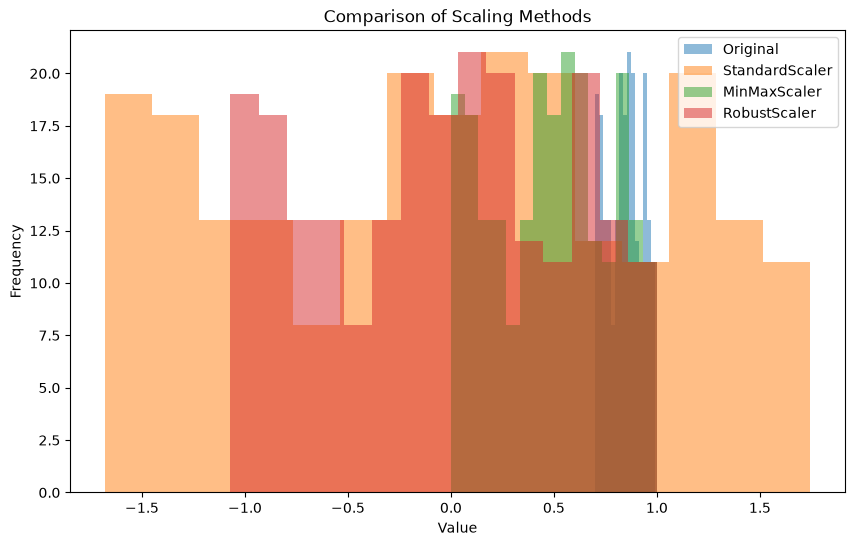

In [10]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.hist(data["confidence"], bins=15, alpha=0.5, label="Original")
plt.hist(data["confidence_standard"], bins=15, alpha=0.5, label="StandardScaler")
plt.hist(data["confidence_minmax"], bins=15, alpha=0.5, label="MinMaxScaler")
plt.hist(data["confidence_robust"], bins=15, alpha=0.5, label="RobustScaler")

plt.xlabel("Value")
plt.ylabel("Frequency")
plt.title("Comparison of Scaling Methods")
plt.legend()
plt.show()

## Scaling Comparison

- **StandardScaler:** Centers the data around a mean of 0 and scales it to a standard deviation of 1. It is useful when the data is approximately normally distributed.
- **MinMaxScaler:** Scales values to a fixed range, usually 0 to 1. It is easy to interpret but can be affected by outliers.
- **RobustScaler:** Uses the median and interquartile range (IQR), making it more resistant to outliers.

**Create numerical text features**

In [11]:
data["text_length"] = data["text"].str.len()
data["word_count"] = data["text"].str.split().str.len()
data["uppercase_count"] = data["text"].str.count(r"[A-Z]")
data["question_count"] = data["text"].str.count(r"\?")
    
data[[
    "confidence",
    "text_length",
    "word_count",
    "uppercase_count",
    "question_count"
]].head()

,confidence,text_length,word_count,uppercase_count,question_count
0,0.77,18,4,1,1
1,0.91,28,5,1,1
2,0.75,21,4,1,0
3,0.83,28,4,1,0
4,0.90,25,5,1,1


**Select the top 5 features**

In [12]:
from sklearn.feature_selection import SelectKBest, f_classif

features = [
    "confidence",
    "text_length",
    "word_count",
    "uppercase_count",
    "question_count"
]

X = data[features]
y = data["intent_label"]

selector = SelectKBest(score_func=f_classif, k=5)

X_selected = selector.fit_transform(X, y)

selected_features = X.columns[selector.get_support()]

print("Top 5 selected features:")
print(selected_features.tolist())

Top 5 selected features:
['confidence', 'text_length', 'word_count', 'uppercase_count', 'question_count']


## Feature Selection with SelectKBest

`SelectKBest` was used with the ANOVA F-test (`f_classif`) to evaluate the relationship between each numerical feature and the target variable.

The five candidate features were:
- confidence
- text_length
- word_count
- uppercase_count
- question_count

The top 5 selected features were identified using `SelectKBest`.

## Week 2 Summary

- Applied LabelEncoder to categorical intent labels.
- Applied OneHotEncoder to represent intent categories as binary features.
- Applied OrdinalEncoder to an ordered confidence-level feature.
- Compared StandardScaler, MinMaxScaler, and RobustScaler.
- Created numerical features from the text data.
- Used SelectKBest with ANOVA F-test to select the top 5 features.